(ortools-number-link)=
# 数回：用回路把数字的对连起来

## 本章的内容

[Z3 一章](z3-number-link)用格的值与线的约束解开了数回，而 CP-SAT 有 `add_circuit()`，因此可以把数字的对表示成一个回路。

- 每个数字的对各造一个带自环的回路
- 每一格只属于其中一个回路
- 回路的路径用 `get_circuit()` 取出

In [1]:
import numpy as np
from ortools.sat.python import cp_model
from helper.ortools import get_circuit

## 盘面

`0` 是空格，1 以上的数值是成对的数字。

In [2]:
board = np.loadtxt('data/numberlink01.txt', dtype=np.uint8)
print(board)

[[1 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 5 0]
 [0 6 0 1 0 0 0 0 0 0]
 [0 0 0 0 0 4 3 0 0 0]
 [0 0 0 0 0 0 6 0 5 0]
 [0 8 0 3 0 0 0 0 0 0]
 [0 0 0 4 7 0 0 0 0 0]
 [0 0 0 0 0 0 2 0 8 0]
 [0 7 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 2]]


## 思路

按数字对的个数分别造出回路。例如数字 1 的那一对，就是一条经过这两个格的回路，其余的格都通过自环跳过，因此不同数字的回路不会互相干扰。

1. 每个回路都包含全部格的有向边与每格的自环
   - 自环 `(i, i)` 表示这一格不属于这个回路
2. 对数字对 `n1`、`n2`，必须使用边 `(n2, n1)`
   - 这样就有了 `n2 → … → n1` 的路径，整体成为一条回路
3. 对每一格，自环为假的回路恰好一个
   - 也就是这一格只属于一个数字的路径

有了第 3 条，线不会交叉，同一个格也不会被两个数字同时占用。这样每条线都只连接一对数字，互不干扰，盘面上不会出现多余的分支。

## 造出格与边

In [3]:
def create_nodes_edges(board):
    """给每个方格编号，并建立相邻方格之间的有向边"""
    h, w = board.shape
    nodes = np.arange(w * h).reshape((h, w))
    edges = []
    for r in range(h):
        for c in range(w):
            node = nodes[r, c]
            if c + 1 < w:
                right = nodes[r, c + 1]
                edges.extend([(node, right), (right, node)])
            if r + 1 < h:
                bottom = nodes[r + 1, c]
                edges.extend([(node, bottom), (bottom, node)])
    return nodes, edges

## 求解

In [4]:
def solve_number_link(board):
    """求解数回，返回（线，每个方格的数字）"""
    h, w = board.shape
    model = cp_model.CpModel()
    nodes, edges = create_nodes_edges(board)

    number_starts = {}      # 数字 → 起点的方格编号
    layers_circuits = {}    # 数字 → 有向边的变量
    layers_nodes = {}       # 数字 → 自环的变量

    for n in range(1, int(board.max()) + 1):
        r, c = np.where(board == n)
        node1 = nodes[r[0], c[0]]
        node2 = nodes[r[1], c[1]]

        circuit_variables = [(s, t, model.new_bool_var(f"{n}_{s}_{t}")) for s, t in edges]
        node_variables = [(s, s, model.new_bool_var(f"{n}_{s}_{s}")) for s in nodes.ravel()]

        # 一定经过 node2 → node1（做成连接这一对的回路）
        model.add_circuit(circuit_variables + node_variables + [(node2, node1, True)])

        number_starts[n] = node1
        layers_circuits[n] = circuit_variables
        layers_nodes[n] = node_variables

    # 每个方格只属于一条回路（自环为假的只有一个）
    for node in nodes.ravel():
        variables = [value[node][2] for value in layers_nodes.values()]
        model.add_exactly_one([~v for v in variables])

    solver = cp_model.CpSolver()
    if solver.solve(model) not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        raise ValueError("没有找到解")

    links = {}
    cells = {}
    for number, circuits in layers_circuits.items():
        solution = {(s, t): solver.value(v) for s, t, v in circuits}
        path = get_circuit(solution, start=number_starts[number])
        path = [(p // w, p % w) for p in path]
        for p in path:
            cells[p] = number
        for p1, p2 in zip(path[:-1], path[1:]):
            links[p1 + p2] = True
    return links, cells

## 运行

用 `helper.plot.plot_number_link_board()` 画出盘面与解出的线。

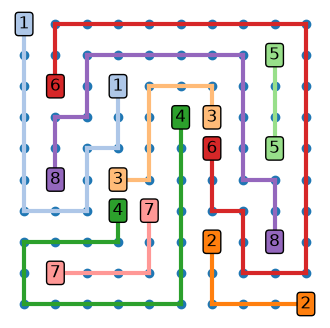

In [5]:
from helper.plot import plot_number_link_board

links, cells = solve_number_link(board)
plot_number_link_board(board, links, cells);

## 更复杂的谜题

CPU times: total: 10.5 s
Wall time: 2.29 s


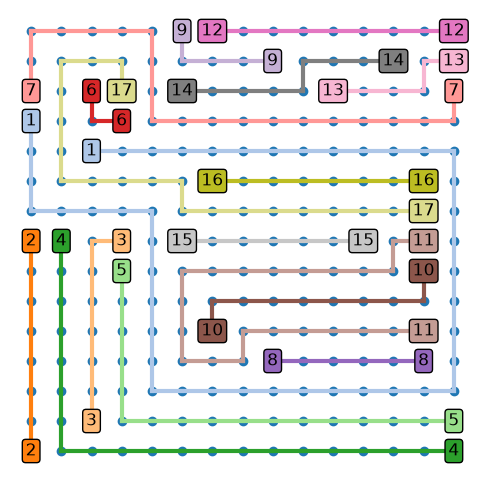

In [6]:
%%time
board = np.loadtxt('data/numberlink02.txt', dtype=np.uint8)
links, cells = solve_number_link(board)
plot_number_link_board(board, links, cells);

## 验算

确认每个数字的路径是否正确地连接了两个数字格。

In [7]:
def check_number_link(board, cells):
    """每个数字的路径，是否成为连接两个数字方格的一条线"""
    groups = {}
    for pos, n in cells.items():
        groups.setdefault(n, set()).add(pos)

    for n in range(1, int(board.max()) + 1):
        group = groups.get(n, set())
        ends = {(r, c) for r, c in zip(*np.where(board == n))}
        if not ends <= group:
            return False, f"{n} 的数字方格不在路径里"

        # 是否连通
        start = next(iter(group))
        seen = {start}
        stack = [start]
        while stack:
            r, c = stack.pop()
            for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
                nb = (r + dr, c + dc)
                if nb in group and nb not in seen:
                    seen.add(nb)
                    stack.append(nb)
        if seen != group:
            return False, f"{n} 的路径断了"

        # 端点只有 2 个（其他都是 2 条连着）
        degree = {}
        for (r, c) in group:
            degree[r, c] = sum(1 for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1))
                               if (r + dr, c + dc) in group)
        if {p for p, d in degree.items() if d == 1} != ends:
            return False, f"{n} 的路径端点和数字方格不一致"
        if any(d > 2 for d in degree.values()):
            return False, f"{n} 的路径分叉了"

    return True, f"{int(board.max())} 条路径都正确连接起来了"


print(check_number_link(board, cells))

(True, '17 条路径都正确连接起来了')


## 小结

- 为每个数字对造一个 `add_circuit()`，并强制经过 `(n2, n1)`，就得到连接那两个格的路径
- 给每格准备自环，并要求自环为假的回路只有一个，这一格就只属于一条路径
- 关键是把编号从大到小回去的边固定下来，这样回路就变成一条开放的路径
- 与 Z3 的写法相比，即值与线的约束，代码要短得多